# 🍷 **Wine Clustering Project**

**Unsupervised Machine Learning | K-Means | PCA | Hierarchical Clustering**

This project groups wines according to their **chemical characteristics**.  
The goal is to discover natural patterns in the data without using a target variable.

**Dataset:** Wine Dataset for Clustering  
**Source:** Kaggle – Harry Wang  
<a href='https://www.kaggle.com/datasets/harrywang/wine-dataset-for-clustering' target='_blank'>
Click here for the dataset
</a>


## 1. Introduction

The dataset contains chemical analysis results for wines produced in the same region of Italy.  
Each wine sample is described by **13 numerical chemical features**.

The Kaggle clustering file contains only the feature columns, so this notebook treats the task as an **Unsupervised Learning / Clustering** problem.

We use **K-Means** as the main clustering algorithm and support the analysis with the **Elbow Method, Silhouette Score, PCA, and Hierarchical Clustering**.


## 2. Problem Definition

**Project Question:**  
Can wines be grouped into meaningful segments using only their chemical composition?

**Machine Learning Type:** Unsupervised Learning  
**Main Algorithm:** K-Means Clustering  
**Evaluation:** Silhouette Score + Elbow Method

The clusters can help compare chemically similar wines, understand different chemical profiles, and organize samples into data-driven segments.


## 3. Data Dictionary

| Feature | Description |
|---|---|
| Alcohol | Alcohol content |
| Malic_Acid | Malic acid level |
| Ash | Ash content |
| Ash_Alcanity | Alkalinity of ash |
| Magnesium | Magnesium content |
| Total_Phenols | Total phenol content |
| Flavanoids | Flavanoid content |
| Nonflavanoid_Phenols | Non-flavanoid phenol content |
| Proanthocyanins | Proanthocyanin content |
| Color_Intensity | Color intensity |
| Hue | Hue measurement |
| OD280 | OD280/OD315 measurement of diluted wines |
| Proline | Proline content |


## 4. Import Libraries


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

## 5. Load Data

Place `wine-clustering.csv` in the same folder as this notebook before running the project.


In [2]:
df = pd.read_csv('wine-clustering.csv')

df.head()

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


## 6. Exploratory Data Analysis


In [3]:
df.shape

(178, 13)

In [4]:
df.columns

Index(['Alcohol', 'Malic_Acid', 'Ash', 'Ash_Alcanity', 'Magnesium',
       'Total_Phenols', 'Flavanoids', 'Nonflavanoid_Phenols',
       'Proanthocyanins', 'Color_Intensity', 'Hue', 'OD280', 'Proline'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Alcohol               178 non-null    float64
 1   Malic_Acid            178 non-null    float64
 2   Ash                   178 non-null    float64
 3   Ash_Alcanity          178 non-null    float64
 4   Magnesium             178 non-null    int64  
 5   Total_Phenols         178 non-null    float64
 6   Flavanoids            178 non-null    float64
 7   Nonflavanoid_Phenols  178 non-null    float64
 8   Proanthocyanins       178 non-null    float64
 9   Color_Intensity       178 non-null    float64
 10  Hue                   178 non-null    float64
 11  OD280                 178 non-null    float64
 12  Proline               178 non-null    int64  
dtypes: float64(11), int64(2)
memory usage: 18.2 KB


In [6]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
Malic_Acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
Ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
Ash_Alcanity,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
Magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
Total_Phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
Flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
Nonflavanoid_Phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
Proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
Color_Intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


In [7]:
df.isnull().sum()

Alcohol                 0
Malic_Acid              0
Ash                     0
Ash_Alcanity            0
Magnesium               0
Total_Phenols           0
Flavanoids              0
Nonflavanoid_Phenols    0
Proanthocyanins         0
Color_Intensity         0
Hue                     0
OD280                   0
Proline                 0
dtype: int64

In [8]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


### First Observation

The dataset is already very clean:

- **178 wine samples**
- **13 numerical features**
- **0 missing values**
- **0 duplicate rows**

No target variable is available, which confirms the clustering approach

## 7. Data Visualization


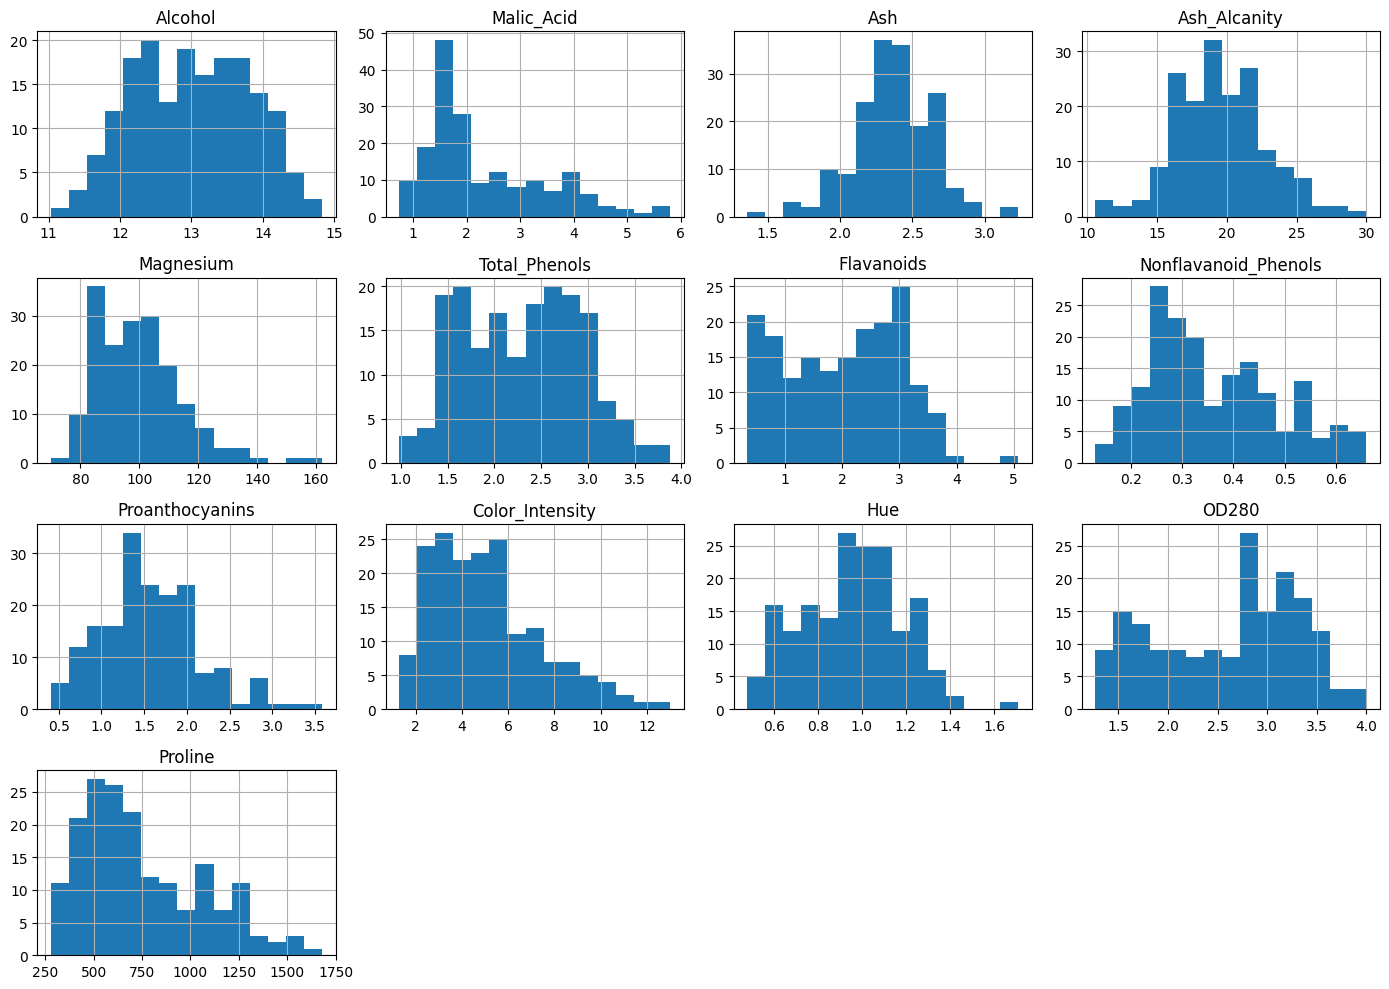

In [9]:
df.hist(figsize=(14, 10), bins=15)
plt.tight_layout()
plt.show()

The distributions show that the variables have very different ranges.  
For example, **Proline** is measured in much larger values than **Hue** or **Ash**.

This is important for distance-based algorithms such as K-Means

## 8. Correlation Heatmap


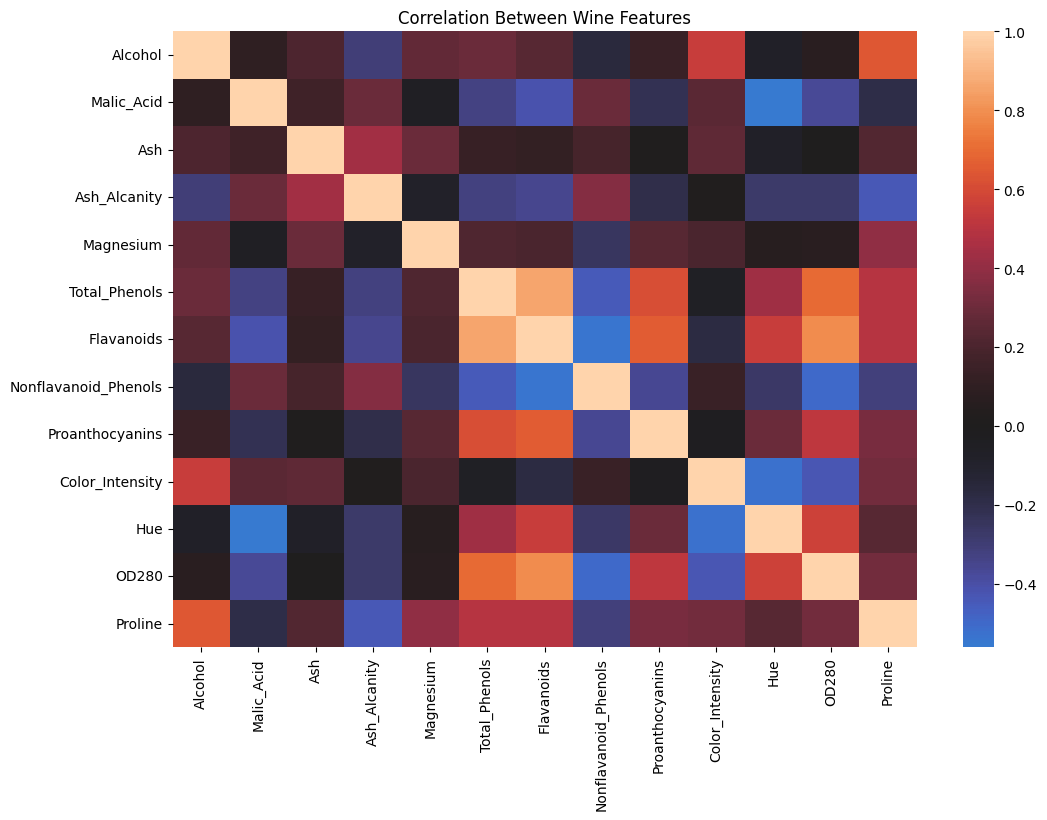

In [10]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), center=0)
plt.title("Correlation Between Wine Features")
plt.show()

Strong relationships can be seen between some chemical characteristics, especially among phenol-related variables.  
Correlation does not define the clusters directly, but it helps us understand the structure of the data.

## 9. Standardization


In [11]:
from sklearn.preprocessing import StandardScaler

x = df.copy()
x_scaled = StandardScaler().fit_transform(x)

K-Means uses distances between observations.  
Because the features use different scales, we standardize them before clustering so that no variable dominates only because of its numerical range.

## 10. Choosing the Number of Clusters


In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

wcss, scores = [], []

for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(x_scaled)
    wcss.append(model.inertia_)
    scores.append(silhouette_score(x_scaled, labels))

### 10.1 Elbow Method


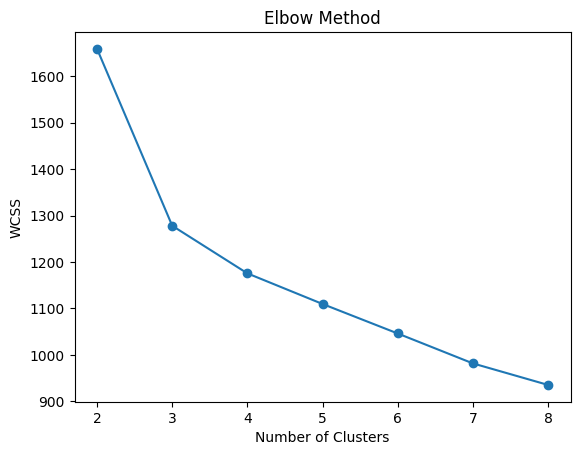

In [13]:
plt.plot(range(2, 9), wcss, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

### 10.2 Silhouette Score


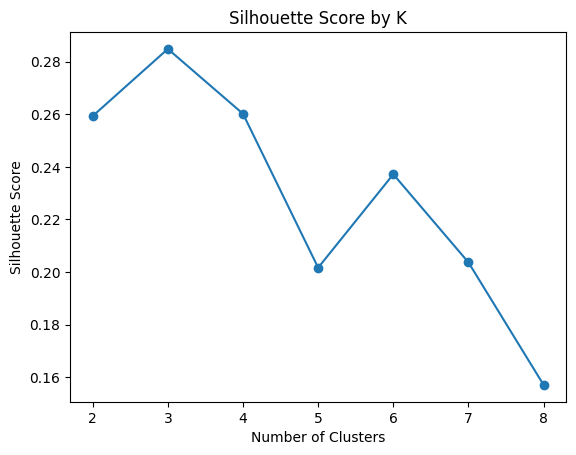

,k,Silhouette
0,2,0.259
1,3,0.285
2,4,0.260
3,5,0.202
4,6,0.237
5,7,0.204
6,8,0.157


In [14]:
plt.plot(range(2, 9), scores, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by K")
plt.show()

pd.DataFrame({"k": range(2, 9), "Silhouette": scores}).round(3)

The **Silhouette Score reaches its highest value at k = 3**.  
The Elbow Method also shows diminishing improvement after a small number of clusters, so we continue with **three clusters**


## 11. K-Means Clustering


In [15]:
model = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster"] = model.fit_predict(x_scaled)

print("Silhouette Score:", round(silhouette_score(x_scaled, df["Cluster"]), 3))
df["Cluster"].value_counts().sort_index()

Silhouette Score: 0.285


Cluster
0    65
1    51
2    62
Name: count, dtype: int64

## 12. Cluster Distribution


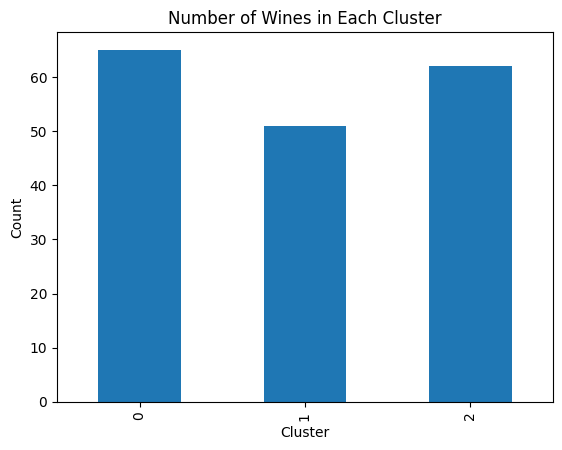

In [16]:
df["Cluster"].value_counts().sort_index().plot(kind="bar")
plt.title("Number of Wines in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Count")
plt.show()

## 13. PCA – 2D Cluster Map


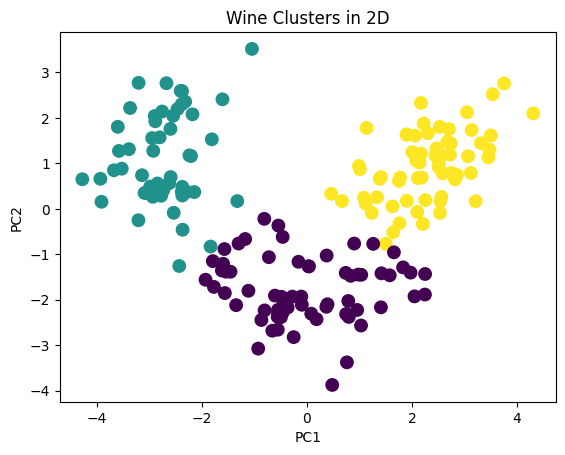

Explained variance: 0.554


In [17]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
points = pca.fit_transform(x_scaled)

pca_df = pd.DataFrame(points, columns=["PC1", "PC2"])
pca_df["Cluster"] = df["Cluster"]

plt.scatter(pca_df["PC1"], pca_df["PC2"], c=pca_df["Cluster"], s=80)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Wine Clusters in 2D")
plt.show()

print("Explained variance:", round(pca.explained_variance_ratio_.sum(), 3))

PCA reduces the 13 original features to two dimensions for visualization.  
The first two components explain about **55% of the total variance**.

The plot shows visible grouping, although the Silhouette Score indicates that the cluster separation is **moderate rather than very strong**.


## 14. Cluster Profiles


In [18]:
profile = df.groupby("Cluster").mean().round(2)
profile

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
Cluster,,,,,,,,,,,,,
0,12.25,1.90,2.23,20.06,92.74,2.25,2.05,0.36,1.62,2.97,1.06,2.80,510.17
1,13.13,3.31,2.42,21.24,98.67,1.68,0.82,0.45,1.15,7.23,0.69,1.70,619.06
2,13.68,2.00,2.47,17.46,107.97,2.85,3.00,0.29,1.92,5.45,1.07,3.16,1100.23


### 14.1 Cluster Profile Heatmap


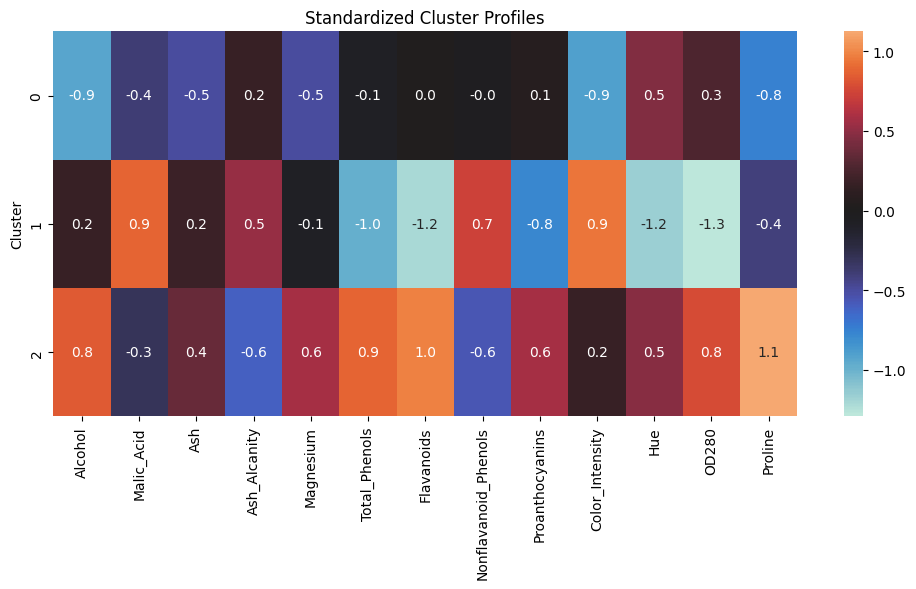

In [19]:
scaled_df = pd.DataFrame(x_scaled, columns=x.columns)
scaled_df["Cluster"] = df["Cluster"]

plt.figure(figsize=(12, 5))
sns.heatmap(scaled_df.groupby("Cluster").mean(), center=0, annot=True, fmt=".1f")
plt.title("Standardized Cluster Profiles")
plt.show()


## 15. Cluster Insights

The clusters represent **different chemical profiles**, not quality scores.

**Cluster 0 – Lower Alcohol & Color Intensity**
- Lower Alcohol
- Lower Color Intensity
- Lower Proline
- Relatively higher Hue

**Cluster 1 – High Malic Acid & Color Intensity**
- Higher Malic Acid
- Higher Color Intensity
- Lower Flavanoids and Total Phenols
- Lower Hue and OD280

**Cluster 2 – Higher Alcohol, Phenols & Proline**
- Higher Alcohol
- Much higher Proline
- Higher Total Phenols and Flavanoids
- Higher Magnesium

These labels are descriptive summaries created for interpretation; they are not official wine categories.


## 16. Simple Interpretation Rules

These are **descriptive patterns**, not hard classification rules:

- **High Proline + high Alcohol + high Flavanoids → often Cluster 2**
- **High Malic Acid + high Color Intensity + low OD280/Hue → often Cluster 1**
- **Lower Alcohol + lower Proline + lower Color Intensity → often Cluster 0**

Possible uses:
- Wine portfolio segmentation
- Product comparison
- Chemical profile exploration
- Detecting unusual samples
- Identifying chemically similar wine groups


## 17. Hierarchical Clustering – Model Comparison


In [20]:
from sklearn.cluster import AgglomerativeClustering

hierarchical = AgglomerativeClustering(n_clusters=3)
h_labels = hierarchical.fit_predict(x_scaled)

print("K-Means:", round(silhouette_score(x_scaled, df["Cluster"]), 3))
print("Hierarchical:", round(silhouette_score(x_scaled, h_labels), 3))


K-Means: 0.285
Hierarchical: 0.277


K-Means has a **slightly higher Silhouette Score** on this dataset.  
The difference is small, but K-Means is also simple to explain and reuse, so it remains the final model for this project.


## 18. Bonus: Interactive 3D PCA


In [21]:
import plotly.express as px

pca3 = PCA(n_components=3).fit_transform(x_scaled)
plot3d = pd.DataFrame(pca3, columns=["PC1", "PC2", "PC3"])
plot3d["Cluster"] = df["Cluster"].astype(str)

px.scatter_3d(
    plot3d,
    x="PC1",
    y="PC2",
    z="PC3",
    color="Cluster",
    title="Interactive 3D Wine Clusters"
)


The 3D chart is optional, but it makes the project more interactive without adding complex code.

## 19. Optional: Save Cluster Results

The original CSV is enough to run the project. If you want a separate results file for Excel or reuse later, uncomment the line below.

In [22]:
# df.to_csv("wine_clustered.csv", index=False)

## 20. Conclusion

This project successfully applied **K-Means Clustering** to group wine samples according to their chemical characteristics.

**Final Result**
- Dataset: **178 wines, 13 features**
- Missing values: **0**
- Duplicate rows: **0**
- Selected clusters: **3**
- Silhouette Score: **~0.285**
- PCA (2 components): **~55% explained variance**

The analysis identifies three interpretable chemical profiles.  
The Silhouette Score suggests **moderate cluster separation**, so the clusters should be interpreted as useful exploratory segments rather than perfectly separated groups.

K-Means provides a simple and interpretable way to discover structure in the dataset without using target labels.

**Final note:** The clusters indicate chemical similarity, not wine quality or ranking.
